# Using Droupout in Regression

In [1]:
import torch 
import torch.nn as nn
import torch.nn.functional as f
import numpy as np
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader, Dataset

torch.manual_seed(0)

## Make some Data

In [2]:
# Create Data object

class Data(Dataset):
    
    # Constructor
    def __init__(self, N_SAMPLES=40, noise_std=1, train=True):
        self.x = torch.linspace(-1, 1, N_SAMPLES).view(-1, 1)
        self.f = self.x ** 2
        if train != True:
            torch.manual_seed(1)
            self.y = self.f + noise_std * torch.randn(self.f.size())
            self.y = self.y.view(-1, 1)
            torch.manual_seed(0)
        else:
            self.y = self.f + noise_std * torch.randn(self.f.size())
            self.y = self.y.view(-1, 1)
            
    # Getter
    def __getitem__(self, index):    
        return self.x[index], self.y[index]
    
    # Get Length
    def __len__(self):
        return self.len
    
    # Plot the data
    def plot(self):
        plt.figure(figsize = (6.1, 10))
        plt.scatter(self.x.numpy(), self.y.numpy(), label="Samples")
        plt.plot(self.x.numpy(), self.f.numpy() ,label="True Function", color='orange')
        plt.xlabel("x")
        plt.ylabel("y")
        plt.xlim((-1, 1))
        plt.ylim((-2, 2.5))
        plt.legend(loc="best")
        plt.show()

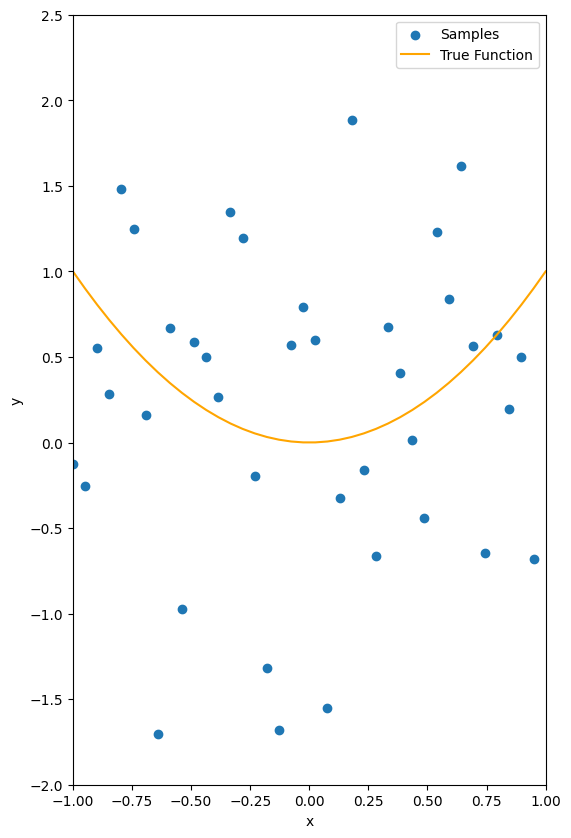

In [3]:
# Create dataset object and plot it
dataset = Data()
dataset.plot()

In [4]:
# create validation dataset object
validation_data = Data(train=False)

## Create the Model, Optimizer, and Total Loss function

In [19]:
# create the class
class n_net(nn.Module):

    # constructor 
    def __init__(self, input_size, n_hidden, output_size, p=0):
        super(n_net, self).__init__()
        self.drop = nn.Dropout(p=p)
        self.linear1 = nn.Linear(input_size, n_hidden)
        self.linear2 = nn.Linear(n_hidden, n_hidden)
        self.linear3 = nn.Linear(n_hidden, output_size)

    def forward(self, x):
        x = f.relu(self.drop(self.linear1(x)))
        x = f.relu(self.drop(self.linear2(x)))
        x = self.linear3(x)
        return x


In [20]:
# create the model objects

model = n_net(1, 300, 1)
model_drop = n_net(1, 300, 1, p=0.5)

## Train the model via Mini-Batch GD

In [21]:
# Set the model to train model

model_drop.train()

n_net(
  (drop): Dropout(p=0.5, inplace=False)
  (linear1): Linear(in_features=1, out_features=300, bias=True)
  (linear2): Linear(in_features=300, out_features=300, bias=True)
  (linear3): Linear(in_features=300, out_features=1, bias=True)
)

In [22]:
# set the optimizer and criterion

optimizer = torch.optim.Adam(model.parameters(), lr=0.01)
optimizer_drop = torch.optim.Adam(model_drop.parameters(), lr=0.01)
criterion = torch.nn.MSELoss()

In [23]:
# the dict to contain the loss results

Loss = {}
Loss['train no drop'] = []
Loss['valid no drop'] = []
Loss['train drop'] = []
Loss['valid drop'] = []

In [24]:
# train the model

def train_model(epochs):
    for epoch in range(epochs):
        yhat = model(dataset.x)
        yhat_drop = model_drop(dataset.x)

        loss = criterion(yhat, dataset.y)
        loss_drop = criterion(yhat_drop, dataset.y)

        # Store the loss
        Loss['train no drop'].append(loss.item())
        Loss['valid no drop'].append(criterion(model(validation_data.x), validation_data.y).item())
        Loss['train drop'].append(loss_drop.item())
        model_drop.eval()
        Loss['valid drop'].append(criterion(model_drop(validation_data.x), validation_data.y).item())
        model_drop.train()

        optimizer.zero_grad()
        optimizer_drop.zero_grad()
        loss.backward()
        loss_drop.backward()
        optimizer.step()
        optimizer_drop.step()


epochs = 500
train_model(epochs)

In [25]:
model_drop.eval()

n_net(
  (drop): Dropout(p=0.5, inplace=False)
  (linear1): Linear(in_features=1, out_features=300, bias=True)
  (linear2): Linear(in_features=300, out_features=300, bias=True)
  (linear3): Linear(in_features=300, out_features=1, bias=True)
)

In [26]:
yhat = model(dataset.x)
yhat_drop = model_drop(dataset.x)

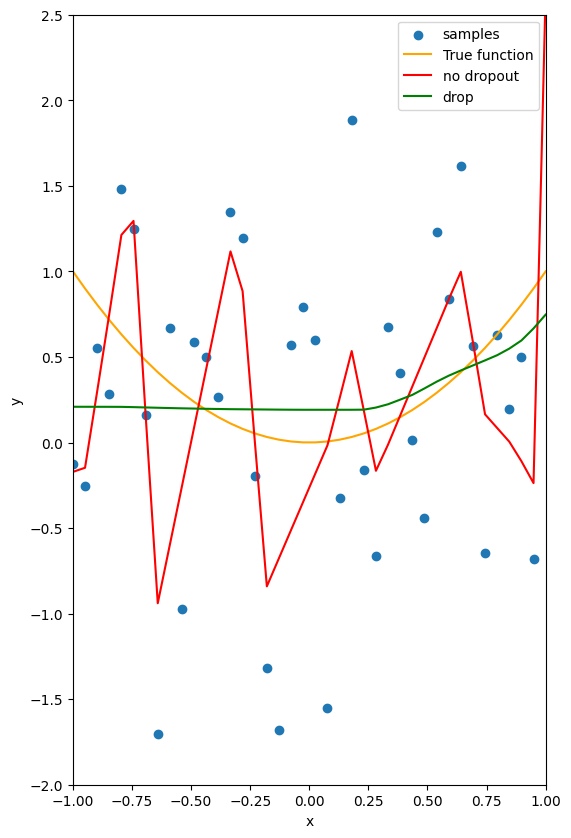

In [28]:
# Plot the prediction 
plt.figure(figsize=(6.1, 10))

plt.scatter(dataset.x.numpy(), dataset.y.numpy(), label="samples")
plt.plot(dataset.x.numpy(), dataset.f.numpy(), label='True function', color='orange')
plt.plot(dataset.x.numpy(), yhat.detach().numpy(), label='no dropout', color='r')
plt.plot(dataset.x.numpy(), yhat_drop.detach().numpy(), label='drop', color='g')

plt.xlabel('x')
plt.ylabel('y')
plt.xlim((-1,1))
plt.ylim((-2, 2.5))
plt.legend(loc='best')

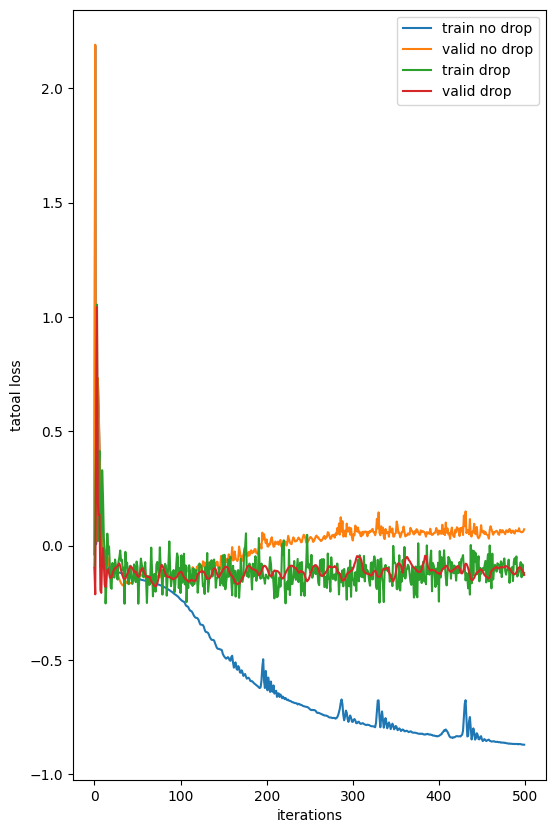

In [29]:
# plot the loss
plt.figure(figsize=(6.1, 10))
for key, value in Loss.items():
    plt.plot(np.log(np.array(value)), label = key)
    plt.legend()
    plt.xlabel("iterations")
    plt.ylabel("tatoal loss")

### You see that the model without dropout performs better on the training data, but it performs worse on the validation data. This suggests overfitting.  However, the model using dropout performs better on the validation data, but worse on the training data. 
